<a href="https://colab.research.google.com/github/KtoxTheNisa/GROUP51_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
from google.colab import userdata
!rm -rf ~/.kaggle
!mkdir -p ~/.kaggle
token = userdata.get('KAGGLE_API_TOKEN')
with open('/root/.kaggle/access_token', 'w') as f:
  f.write(token)
!chmod 600 ~/.kaggle/access_token
print ("oldu")


oldu


In [2]:
!kaggle competitions download -c rohlik-sales-forecasting-challenge-v2

!unzip -q rohlik-sales-forecasting-challenge-v2.zip -d data

100% 47.3M/47.3M [00:00<00:00, 169MB/s]



In [27]:
import pandas as pd

df = pd.read_csv('/content/data/sales_train.csv')
df.head()

,unique_id,date,warehouse,total_orders,sales,sell_price_main,availability,type_0_discount,type_1_discount,type_2_discount,type_3_discount,type_4_discount,type_5_discount,type_6_discount
0,4845,2024-03-10,Budapest_1,6436.0,16.34,646.26,1.00,0.00000,0.0,0.0,0.0,0.15312,0.0,0.0
1,4845,2021-05-25,Budapest_1,4663.0,12.63,455.96,1.00,0.00000,0.0,0.0,0.0,0.15025,0.0,0.0
2,4845,2021-12-20,Budapest_1,6507.0,34.55,455.96,1.00,0.00000,0.0,0.0,0.0,0.15025,0.0,0.0
3,4845,2023-04-29,Budapest_1,5463.0,34.52,646.26,0.96,0.20024,0.0,0.0,0.0,0.15312,0.0,0.0
4,4845,2022-04-01,Budapest_1,5997.0,35.92,486.41,1.00,0.00000,0.0,0.0,0.0,0.15649,0.0,0.0


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_data, check_missing, clean_calendar, clean_sales, normalize_price, merge_tables
from src.models import predict_mean_baseline, predict_median_baseline, train_baseline_models
from src.utils import split_train_val, calculate_metrics, save_submission

In [51]:
#load all dataset tables
sales_train = load_data("data/sales_train.csv")
sales_test = load_data("data/sales_test.csv")
inventory = load_data("data/inventory.csv")
calendar = load_data("data/calendar.csv")
test_weights = load_data("data/test_weights.csv")

#check rows and columns for each table
print("sales_train shape:", sales_train.shape)
print("sales_test shape:", sales_test.shape)
print("inventory shape:", inventory.shape)
print("calendar shape:", calendar.shape)
print("test_weights shape:", test_weights.shape)

sales_train shape: (4007419, 14)
sales_test shape: (47021, 12)
inventory shape: (5432, 8)
calendar shape: (23016, 7)
test_weights shape: (5390, 2)


In [52]:
sales_train.head()

,unique_id,date,warehouse,total_orders,sales,sell_price_main,availability,type_0_discount,type_1_discount,type_2_discount,type_3_discount,type_4_discount,type_5_discount,type_6_discount
0,4845,2024-03-10,Budapest_1,6436.0,16.34,646.26,1.00,0.00000,0.0,0.0,0.0,0.15312,0.0,0.0
1,4845,2021-05-25,Budapest_1,4663.0,12.63,455.96,1.00,0.00000,0.0,0.0,0.0,0.15025,0.0,0.0
2,4845,2021-12-20,Budapest_1,6507.0,34.55,455.96,1.00,0.00000,0.0,0.0,0.0,0.15025,0.0,0.0
3,4845,2023-04-29,Budapest_1,5463.0,34.52,646.26,0.96,0.20024,0.0,0.0,0.0,0.15312,0.0,0.0
4,4845,2022-04-01,Budapest_1,5997.0,35.92,486.41,1.00,0.00000,0.0,0.0,0.0,0.15649,0.0,0.0


In [53]:
inventory.head(3)

,unique_id,product_unique_id,name,L1_category_name_en,L2_category_name_en,L3_category_name_en,L4_category_name_en,warehouse
0,5255,2583,Pastry_196,Bakery,Bakery_L2_14,Bakery_L3_26,Bakery_L4_1,Prague_3
1,4948,2426,Herb_19,Fruit and vegetable,Fruit and vegetable_L2_30,Fruit and vegetable_L3_86,Fruit and vegetable_L4_1,Prague_3
2,2146,1079,Beet_2,Fruit and vegetable,Fruit and vegetable_L2_3,Fruit and vegetable_L3_65,Fruit and vegetable_L4_34,Prague_1


In [54]:
calendar.head(3)

,date,holiday_name,holiday,shops_closed,winter_school_holidays,school_holidays,warehouse
0,2022-03-16,NaN,0,0,0,0,Frankfurt_1
1,2020-03-22,NaN,0,0,0,0,Frankfurt_1
2,2018-02-07,NaN,0,0,0,0,Frankfurt_1


In [55]:
sales_train.dtypes

,0
unique_id,int64
date,object
warehouse,object
total_orders,float64
sales,float64
sell_price_main,float64
availability,float64
type_0_discount,float64
type_1_discount,float64
type_2_discount,float64


In [56]:
sales_train.describe()


,unique_id,total_orders,sales,sell_price_main,availability,type_0_discount,type_1_discount,type_2_discount,type_3_discount,type_4_discount,type_5_discount,type_6_discount
count,4.007419e+06,4.007367e+06,4.007367e+06,4.007419e+06,4.007419e+06,4.007419e+06,4.007419e+06,4.007419e+06,4.007419e+06,4.007419e+06,4.007419e+06,4.007419e+06
mean,2.740801e+03,5.995722e+03,1.083808e+02,1.814199e+02,9.253107e-01,8.518626e-03,1.240899e-04,1.163193e-03,5.452819e-06,5.680178e-03,4.049705e-04,1.045480e-02
std,1.558566e+03,2.479598e+03,3.603327e+02,4.611014e+02,1.796205e-01,5.147027e-02,5.142815e-03,1.879977e-02,8.922436e-04,2.892965e-02,9.199913e-03,5.545035e-02
min,0.000000e+00,4.580000e+02,0.000000e+00,2.000000e-02,1.000000e-02,-2.094930e+01,0.000000e+00,0.000000e+00,0.000000e+00,-4.712000e-02,0.000000e+00,-8.014900e-01
25%,1.398000e+03,4.402000e+03,1.798000e+01,2.113000e+01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.744000e+03,5.515000e+03,3.952000e+01,4.564000e+01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,4.084000e+03,8.011000e+03,9.447000e+01,1.121300e+02,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,5.431000e+03,1.847500e+04,2.631619e+04,2.168299e+04,1.000000e+00,9.916400e-01,5.000000e-01,7.637200e-01,2.506300e-01,4.529000e-01,6.691400e-01,9.000500e-01


In [74]:
print("sales_train missing values:")
print(check_missing(sales_train))
print("\ncalendar missing values:")
print(check_missing(calendar))

sales_train missing values:
total_orders    52
sales           52
dtype: int64

calendar missing values:
holiday_name    22086
dtype: int64


In [58]:
sales_train[sales_train["sales"].isnull()][["unique_id", "date", "warehouse", "total_orders", "sales"]].head()

,unique_id,date,warehouse,total_orders,sales
154017,885,2021-05-23,Munich_1,NaN,NaN
154099,885,2021-05-21,Munich_1,NaN,NaN
154149,885,2021-05-24,Munich_1,NaN,NaN
154155,885,2021-05-22,Munich_1,NaN,NaN
429815,1237,2021-12-10,Frankfurt_1,NaN,NaN


In [59]:
#in calendar holiday_name is NaN by design when holiday is 0
#check how many are missing when holiday is 1
print("Missing when holiday == 0:", calendar[calendar["holiday"] == 0]["holiday_name"].isnull().sum())
print("Missing when holiday == 1:", calendar[calendar["holiday"] == 1]["holiday_name"].isnull().sum())

Missing when holiday == 0: 21920
Missing when holiday == 1: 166


In [60]:
#check for negative discount values
discount_cols = [f"type_{i}_discount" for i in range(7)]
for col in discount_cols:
    neg_count = (sales_train[col] < 0).sum()
    print(f"{col} -> min: {sales_train[col].min()}, negative rows: {neg_count}")

type_0_discount -> min: -20.9493, negative rows: 27
type_1_discount -> min: 0.0, negative rows: 0
type_2_discount -> min: 0.0, negative rows: 0
type_3_discount -> min: 0.0, negative rows: 0
type_4_discount -> min: -0.04712, negative rows: 1
type_5_discount -> min: 0.0, negative rows: 0
type_6_discount -> min: -0.80149, negative rows: 4


In [61]:
sales_train.sort_values("sales", ascending=False)[["unique_id", "warehouse", "date", "sales", "total_orders"]].head(5)

,unique_id,warehouse,date,sales,total_orders
667612,4720,Brno_1,2022-12-23,26316.19,10385.0
667609,4720,Brno_1,2022-12-30,25876.75,10183.0
667810,4720,Brno_1,2021-12-23,25377.02,9940.0
667069,4720,Brno_1,2023-10-14,24626.66,7882.0
738145,4885,Prague_1,2023-12-23,23957.36,18475.0


Mean sales: 108.38
Median sales: 39.52


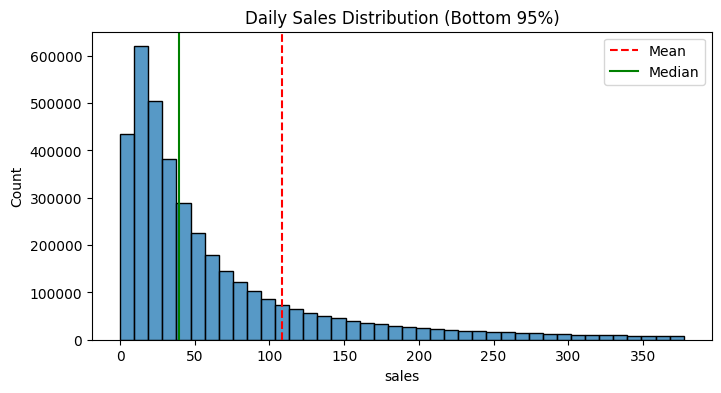

In [62]:
#mean and median of sales
mean_val = sales_train["sales"].mean()
median_val = sales_train["sales"].median()
print(f"Mean sales: {mean_val:.2f}")
print(f"Median sales: {median_val:.2f}")

# plot distribution up to the 95th percentile so outliers don't squash the histogram
upper_limit = sales_train["sales"].quantile(0.95)
plt.figure(figsize=(8, 4))
sns.histplot(sales_train[sales_train["sales"] <= upper_limit]["sales"], bins=40)
plt.axvline(mean_val, color="red", linestyle="--", label="Mean")
plt.axvline(median_val, color="green", label="Median")
plt.title("Daily Sales Distribution (Bottom 95%)")
plt.legend()
plt.show()

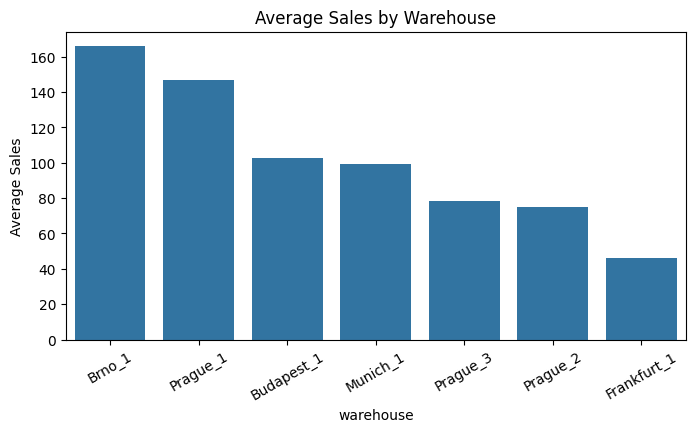

In [63]:
#average sales by warehouse
wh_sales = sales_train.groupby("warehouse")["sales"].mean().sort_values(ascending=False)
plt.figure(figsize=(8, 4))
sns.barplot(x=wh_sales.index, y=wh_sales.values)
plt.title("Average Sales by Warehouse")
plt.ylabel("Average Sales")
plt.xticks(rotation=30)
plt.show()

In [64]:
#warehouses are in different countries so sell_price_main has different scales
sales_train.groupby("warehouse")[["sell_price_main", "total_orders", "sales"]].agg(["mean", "median", "min", "max"])

sell_price_main                         total_orders          \
                       mean  median   min       max         mean  median   
warehouse                                                                  
Brno_1            67.873869   44.64  1.63   1015.51  8196.958822  8241.0   
Budapest_1       918.184147  696.80  0.12  21682.99  5517.653329  5582.0   
Frankfurt_1        2.977863    2.20  0.18     50.15  1421.066435  1440.0   
Munich_1           3.002412    2.18  0.11     38.75  3181.274187  2960.0   
Prague_1          65.941507   43.86  1.66   1112.54  9114.406893  9252.0   
Prague_2          65.624530   43.66  0.02    994.18  4629.169859  4548.0   
Prague_3          67.141527   44.08  2.02    963.01  4862.602626  4861.0   

                                   sales                        
                min      max        mean median  min       max  
warehouse                                                       
Brno_1       2967.0  13867.0  165.814570  55.00  0.0  26316.19  
Budapest_1   2898.0   9277.0  102.934222  47.70  0.0   6231.23  
Frankfurt_1   798.0   2143.0   46.116097  27.31  0.0   1883.75  
Munich_1      458.0   7666.0   99.519923  54.50  0.0   3429.84  
Prague_1     2466.0  18475.0  146.635053  51.99  0.0  23957.36  
Prague_2     1633.0   9999.0   75.200678  25.71  0.0  12180.19  
Prague_3     1408.0   8429.0   78.314883  27.72  0.0  11549.61

In [65]:
#clean calendar and sales tables
cal_clean = clean_calendar(calendar)
train_clean = clean_sales(sales_train, is_train=True)
test_clean = clean_sales(sales_test, is_train=False)
print("Remaining missing values in train:", train_clean.isnull().sum().sum())
print("Remaining missing values in calendar:", cal_clean.isnull().sum().sum())

Remaining missing values in train: 0
Remaining missing values in calendar: 0


In [66]:
#normalize price per warehouse
train_norm = normalize_price(train_clean)
test_norm = normalize_price(test_clean)
train_norm.groupby("warehouse")[["sell_price_main", "price_norm"]].agg(["min", "mean", "max"])

sell_price_main                       price_norm               
                        min        mean       max        min      mean  max
warehouse                                                                  
Brno_1                 1.63   67.873869   1015.51        0.0  0.065337  1.0
Budapest_1             0.12  918.184147  21682.99        0.0  0.042341  1.0
Frankfurt_1            0.18    2.977871     50.15        0.0  0.055991  1.0
Munich_1               0.11    3.002305     38.75        0.0  0.074853  1.0
Prague_1               1.66   65.941507   1112.54        0.0  0.057865  1.0
Prague_2               0.02   65.624530    994.18        0.0  0.065990  1.0
Prague_3               2.02   67.141527    963.01        0.0  0.067765  1.0

In [67]:
#merge with inventory and calendar
print("Train shape before merge:", train_norm.shape)
train_merged = merge_tables(train_norm, inventory, cal_clean)
test_merged = merge_tables(test_norm, inventory, cal_clean)
del train_clean, train_norm
print("Train shape after merge:", train_merged.shape)
print("Test shape after merge:", test_merged.shape)
train_merged.head(3)

Train shape before merge: (4007367, 16)
Train shape after merge: (4007367, 23)
Test shape after merge: (47021, 21)


,unique_id,date,warehouse,total_orders,sales,sell_price_main,availability,type_0_discount,type_1_discount,type_2_discount,...,type_6_discount,max_discount,price_norm,product_unique_id,L1_category_name_en,L2_category_name_en,holiday,shops_closed,winter_school_holidays,school_holidays
0,4845,2024-03-10,Budapest_1,6436.0,16.34,646.26,1.0,0.0,0.0,0.0,...,0.0,0.15312,0.029800,2375,Bakery,Bakery_L2_18,0,0,0,0
1,4845,2021-05-25,Budapest_1,4663.0,12.63,455.96,1.0,0.0,0.0,0.0,...,0.0,0.15025,0.021023,2375,Bakery,Bakery_L2_18,0,0,0,0
2,4845,2021-12-20,Budapest_1,6507.0,34.55,455.96,1.0,0.0,0.0,0.0,...,0.0,0.15025,0.021023,2375,Bakery,Bakery_L2_18,0,0,0,0


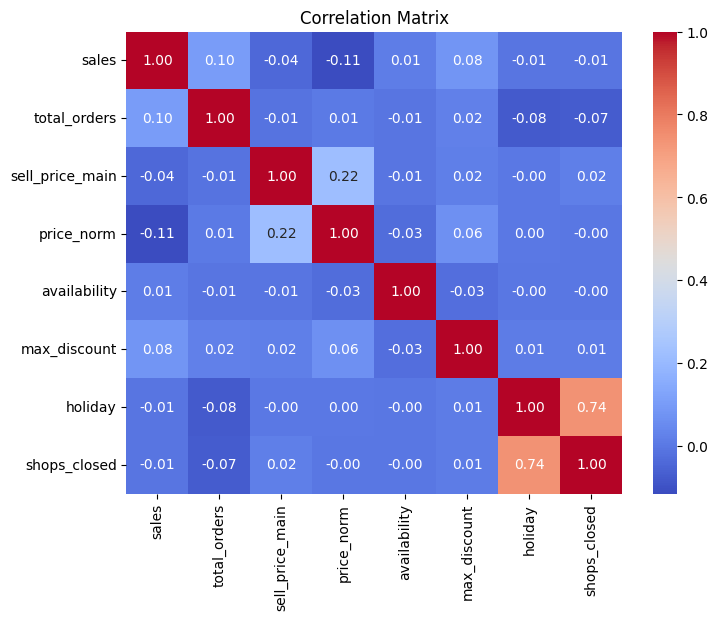

In [68]:
#correlation matrix
cols = ["sales", "total_orders", "sell_price_main", "price_norm", "availability", "max_discount", "holiday", "shops_closed"]
plt.figure(figsize=(8, 6))
sns.heatmap(train_merged[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

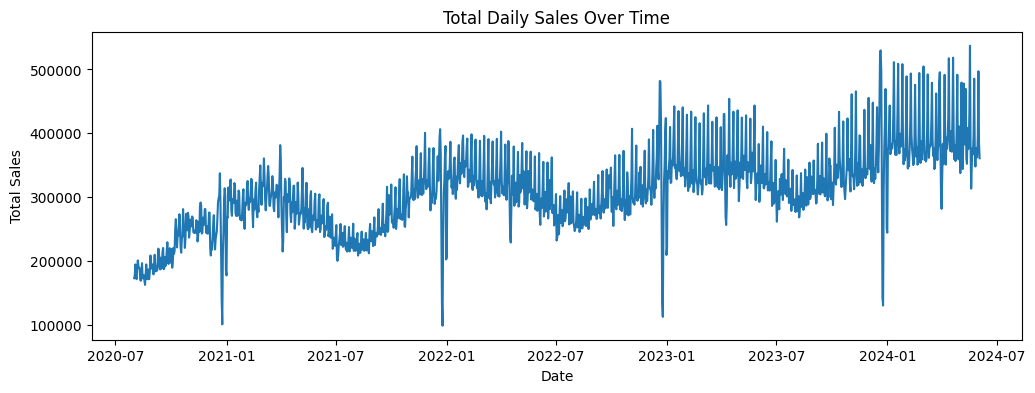

In [69]:
#total daily sales over time
daily_sales = train_merged.groupby("date")["sales"].sum()
daily_sales.index = pd.to_datetime(daily_sales.index)
plt.figure(figsize=(12, 4))
plt.plot(daily_sales.index, daily_sales.values)
plt.title("Total Daily Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.show()

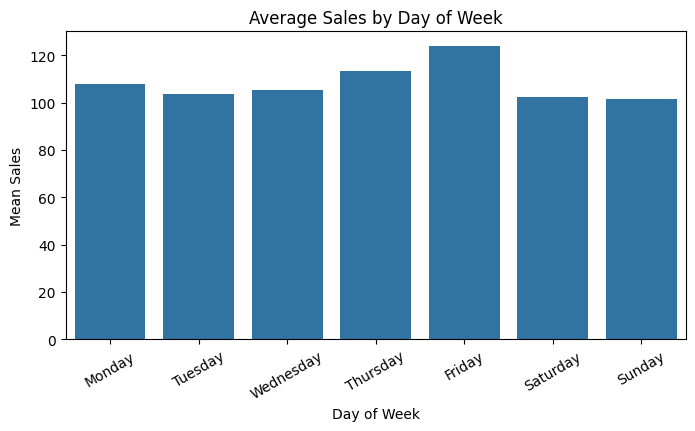

In [70]:
#average sales by day of week
train_merged["day_name"] = pd.to_datetime(train_merged["date"]).dt.day_name()
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_sales = train_merged.groupby("day_name")["sales"].mean().reindex(day_order)
plt.figure(figsize=(8, 4))
sns.barplot(x=day_sales.index, y=day_sales.values)
plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Mean Sales")
plt.xticks(rotation=30)
plt.show()

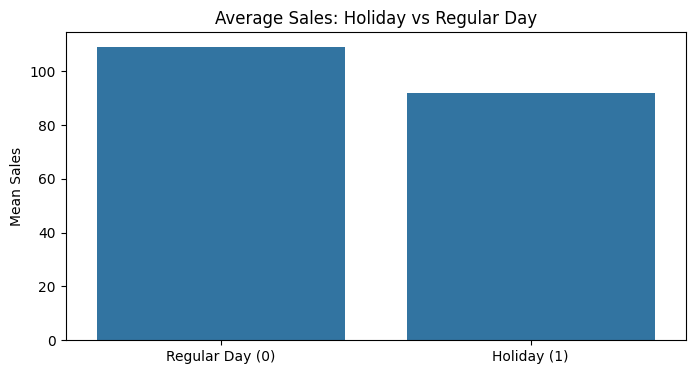

In [71]:
#average sales on holidays vs regular days
hol_sales = train_merged.groupby("holiday")["sales"].mean()
plt.figure(figsize=(8, 4))
sns.barplot(x=["Regular Day (0)", "Holiday (1)"], y=hol_sales.values)
plt.title("Average Sales: Holiday vs Regular Day")
plt.ylabel("Mean Sales")
plt.show()

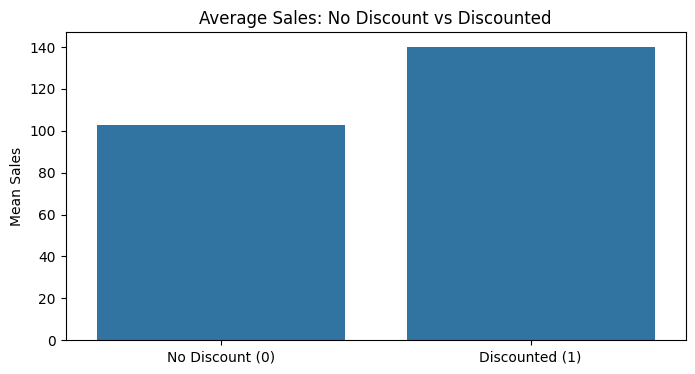

In [72]:
#average sales with discount vs no discount
train_merged["has_discount"] = (train_merged["max_discount"] > 0).astype(int)
disc_sales = train_merged.groupby("has_discount")["sales"].mean()
plt.figure(figsize=(8, 4))
sns.barplot(x=["No Discount (0)", "Discounted (1)"], y=disc_sales.values)
plt.title("Average Sales: No Discount vs Discounted")
plt.ylabel("Mean Sales")
plt.show()

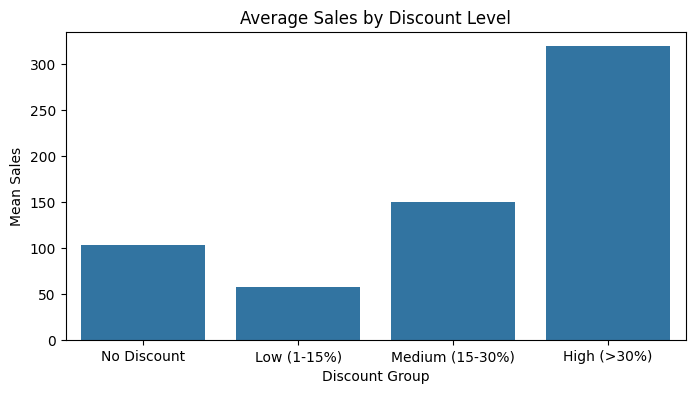

In [73]:
#average sales by discount level
train_merged["discount_group"] = pd.cut(
    train_merged["max_discount"],
    bins=[-0.01, 0.0, 0.15, 0.30, 1.0],
    labels=["No Discount", "Low (1-15%)", "Medium (15-30%)", "High (>30%)"]
)
disc_sales = train_merged.groupby("discount_group", observed=False)["sales"].mean()
plt.figure(figsize=(8, 4))
sns.barplot(x=disc_sales.index, y=disc_sales.values)
plt.title("Average Sales by Discount Level")
plt.xlabel("Discount Group")
plt.ylabel("Mean Sales")
plt.show() #discount vs no discount looks like discount always helps, check by discount level